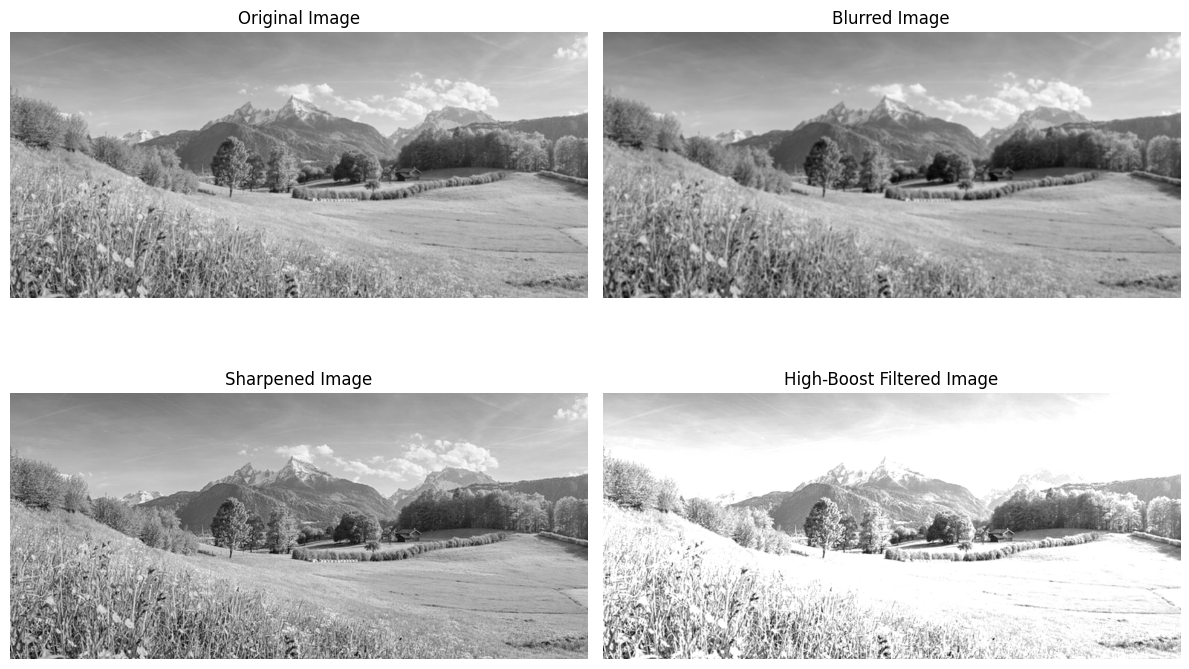

High-Boost Filtering completed.


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


img = cv2.imread("/content/Screenshot 2026-08-28 201335.png", cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: Image not found.")
    exit()

img = img.astype(np.float32)

blurred = cv2.GaussianBlur(img, (5, 5), 0)

high_frequency = img - blurred

sharpened = img + high_frequency

A = 1.5

high_boost = (A - 1) * img + sharpened

high_boost = np.clip(high_boost, 0, 255).astype(np.uint8)
sharpened = np.clip(sharpened, 0, 255).astype(np.uint8)
blurred = np.clip(blurred, 0, 255).astype(np.uint8)

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(img.astype(np.uint8), cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(blurred, cmap="gray")
plt.title("Blurred Image")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(sharpened, cmap="gray")
plt.title("Sharpened Image")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(high_boost, cmap="gray")
plt.title("High-Boost Filtered Image")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite("high_boost_result.jpg", high_boost)

print("High-Boost Filtering completed.")

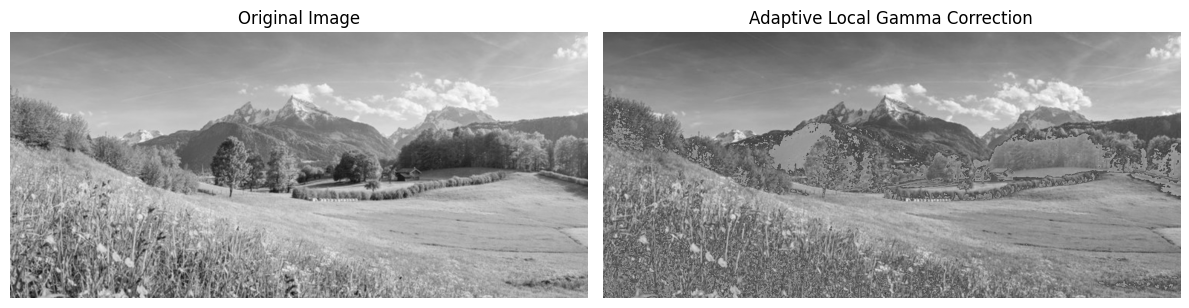

Adaptive Local Enhancement completed.


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("/content/Screenshot 2026-08-28 201335.png", cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: Image not found.")
    exit()

normalized = img.astype(np.float32) / 255.0

gamma_dark = 0.5
gamma_bright = 1.5

threshold = 100

dark_mask = img < threshold
bright_mask = img >= threshold

adaptive_gamma = np.zeros_like(normalized)

adaptive_gamma[dark_mask] = (
    normalized[dark_mask] ** gamma_dark
)

adaptive_gamma[bright_mask] = (
    normalized[bright_mask] ** gamma_bright
)

adaptive_gamma = np.clip(
    adaptive_gamma * 255,
    0,
    255
).astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(adaptive_gamma, cmap="gray")
plt.title("Adaptive Local Gamma Correction")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite(
    "adaptive_gamma_result.jpg",
    adaptive_gamma
)

print("Adaptive Local Enhancement completed.")